In [52]:
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import train_test_split
from sklearn import metrics

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

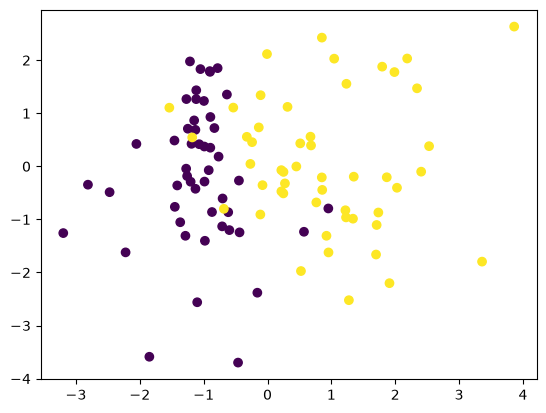

In [53]:
X, y = make_classification(n_samples=100, n_features=2, n_informative=2 ,n_clusters_per_class=2, n_redundant=0, random_state=0)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

In [56]:
class Model:
    def __init__(self, classifier):
        self.classifier = classifier

        self.dokladnosc = []
        self.czulosc = []
        self.precyzja = []
        self.f1 = []


models = [
    Model(GaussianNB()),
    Model(QuadraticDiscriminantAnalysis()),
    Model(KNeighborsClassifier()),
    Model(SVC(probability=True)),
    Model(DecisionTreeClassifier())
]

for model in models:

    for i in range(100):
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

        model.classifier.fit(X_train, y_train)
        y_pred = model.classifier.predict(X_test)

        model.dokladnosc.append(metrics.accuracy_score(y_test, y_pred))
        model.czulosc.append(metrics.recall_score(y_test, y_pred))
        model.precyzja.append(metrics.precision_score(y_test, y_pred))
        model.f1.append(metrics.f1_score(y_test, y_pred))
        metrics.roc_auc(y_test, y_pred)

    df = pd.DataFrame(model.dokladnosc)

    print(df)
        

AttributeError: module 'sklearn.metrics' has no attribute 'roc_auc'